In [5]:
import os
import json
import joblib
import warnings

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [7]:
df=pd.read_csv("/content/creditcard.csv")

In [8]:
df

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


In [9]:
df.tail()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0
284806,172792.0,-0.533413,-0.189733,0.703337,-0.506271,-0.012546,-0.649617,1.577006,-0.414650,0.486180,...,0.261057,0.643078,0.376777,0.008797,-0.473649,-0.818267,-0.002415,0.013649,217.00,0


In [10]:
df.shape

(284807, 31)

In [11]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [12]:
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [14]:
df.isnull().sum()

,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


In [15]:
df.duplicated().sum()

np.int64(1081)

In [16]:
df.drop_duplicates(inplace=True)

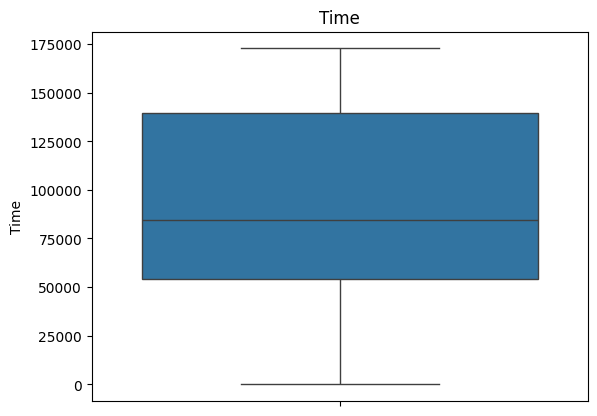

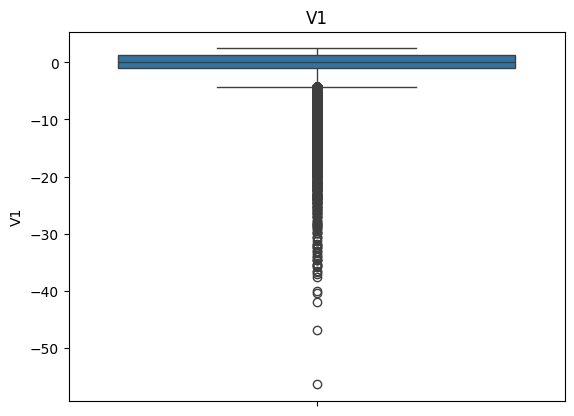

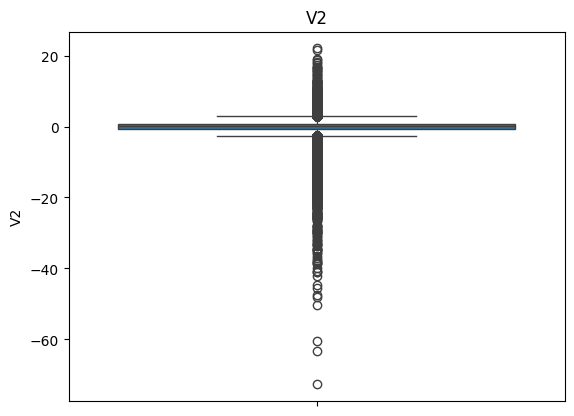

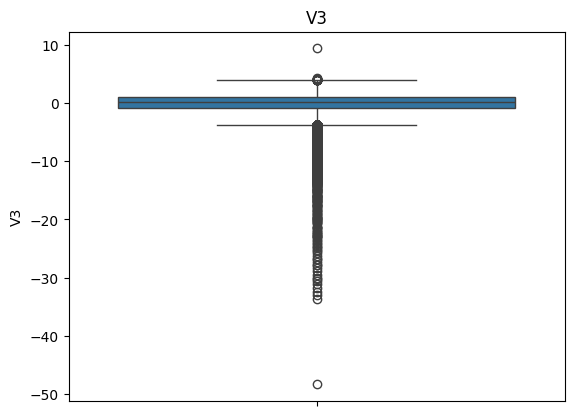

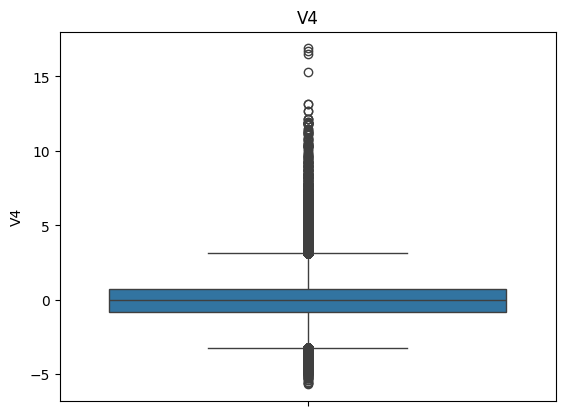

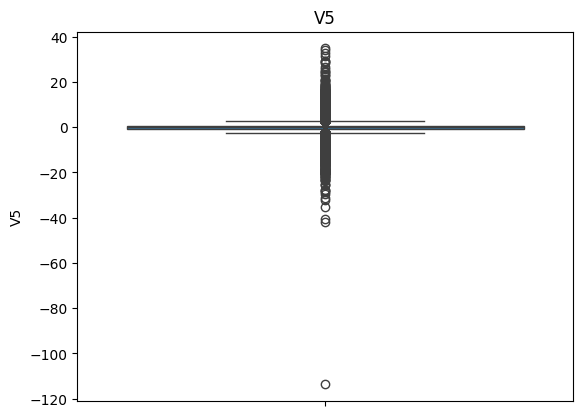

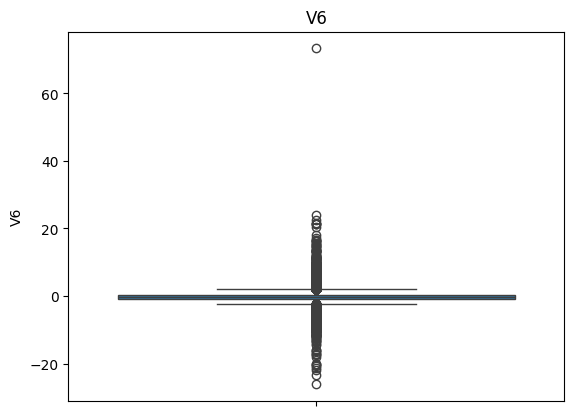

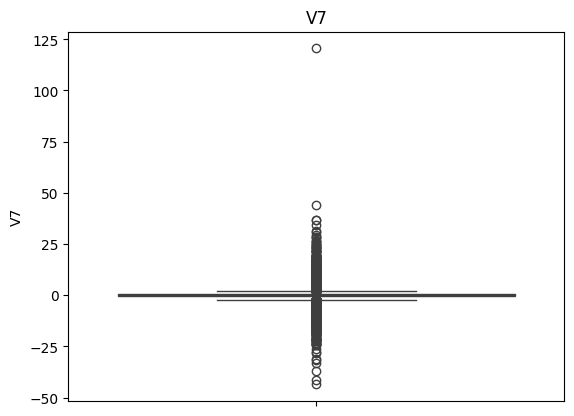

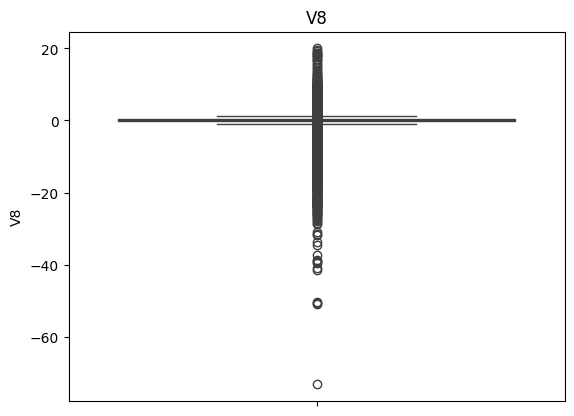

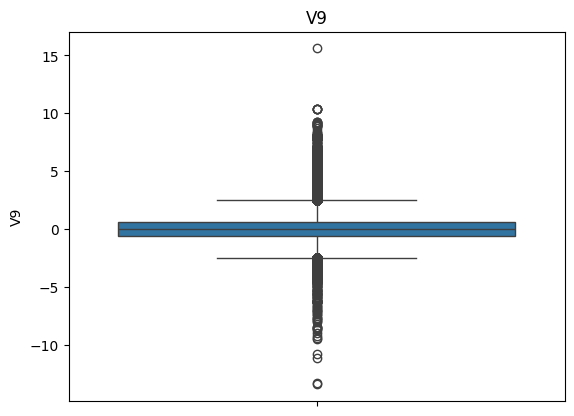

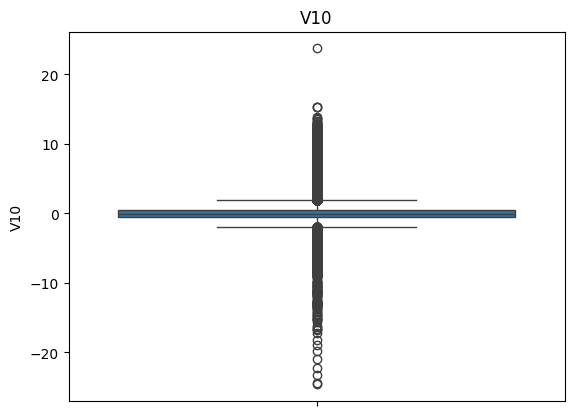

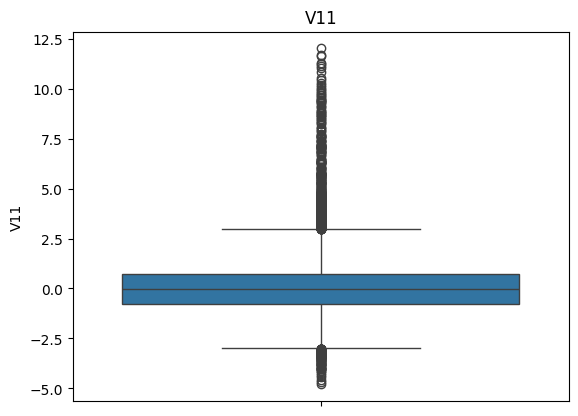

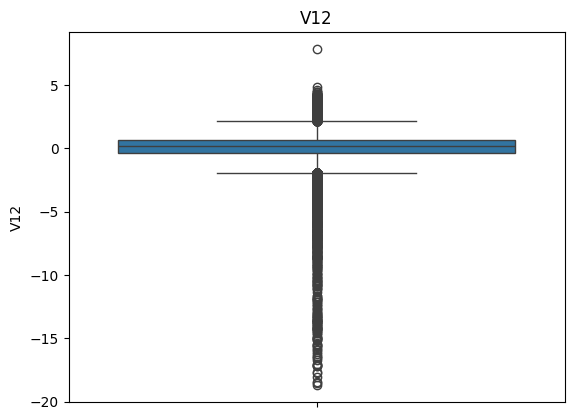

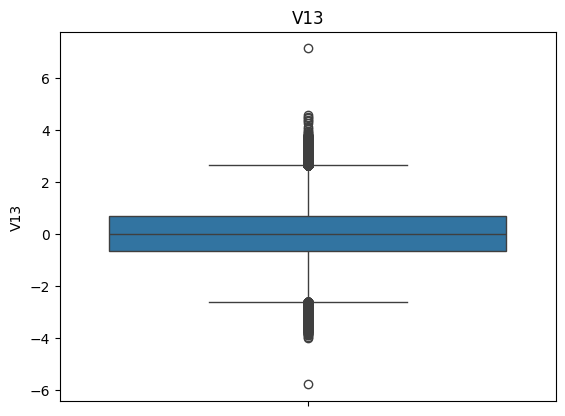

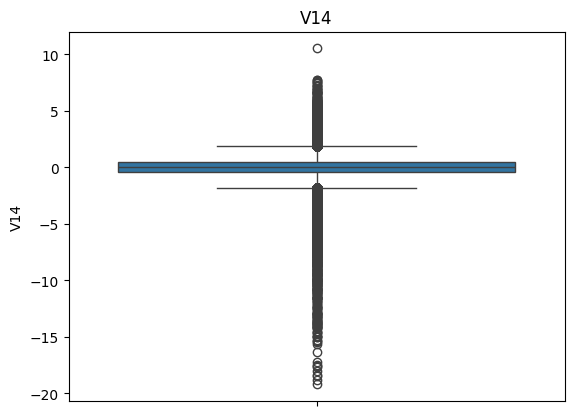

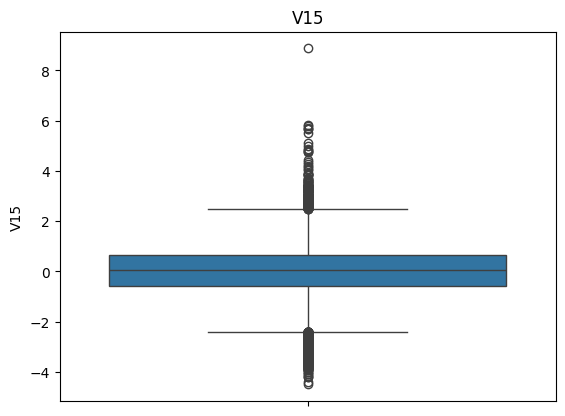

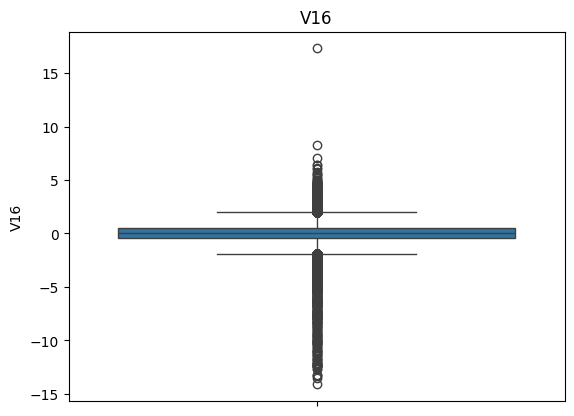

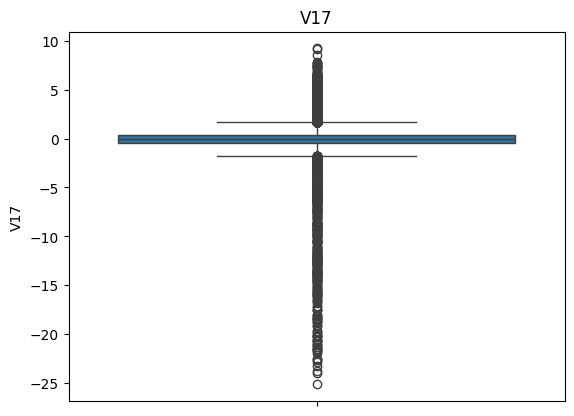

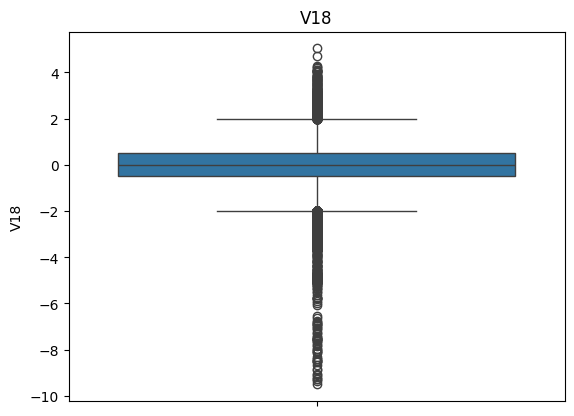

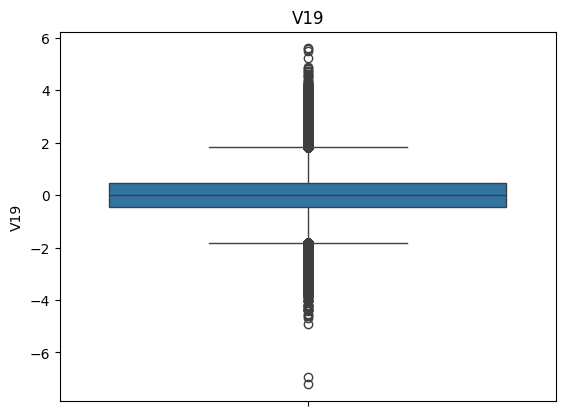

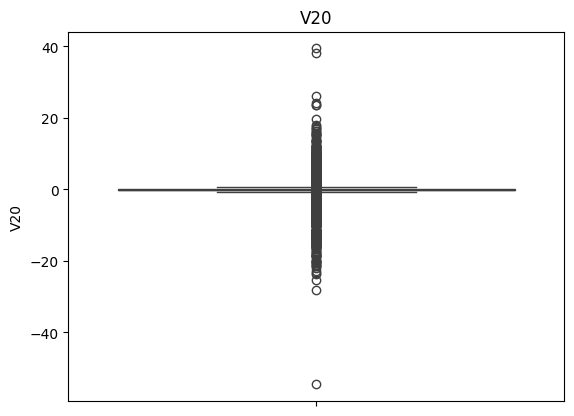

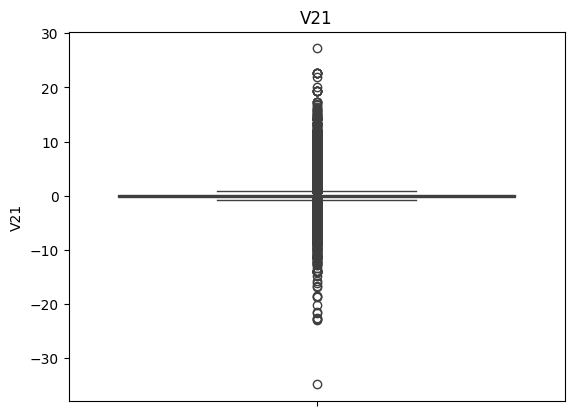

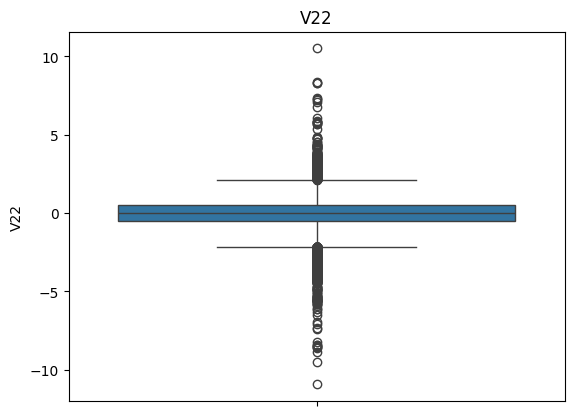

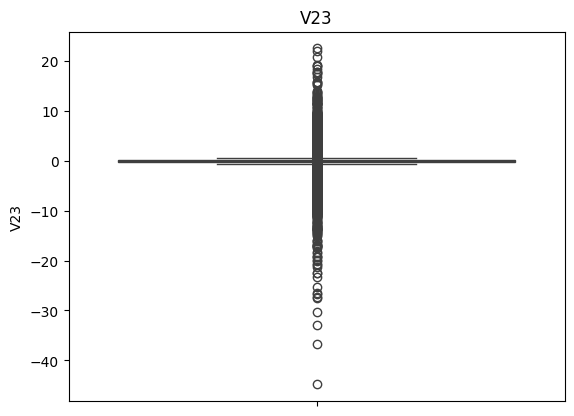

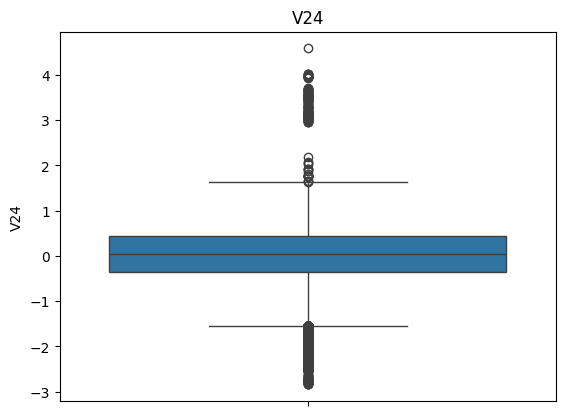

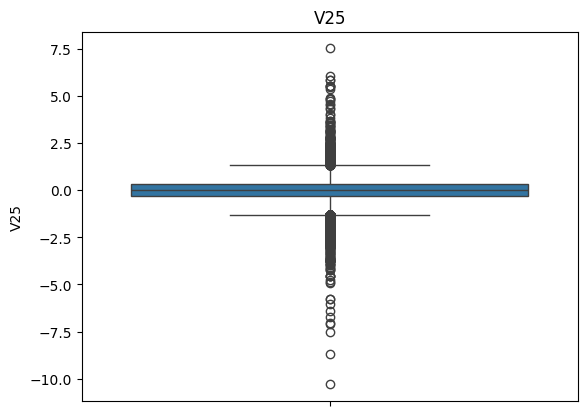

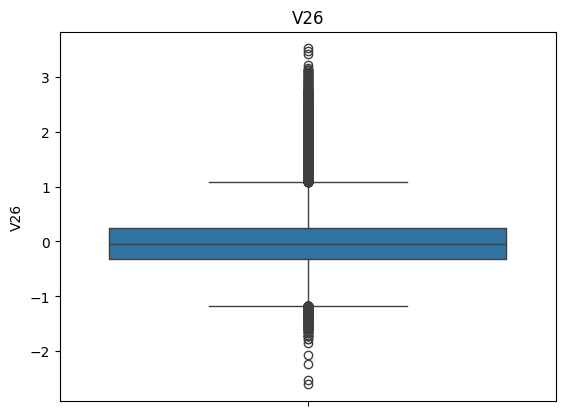

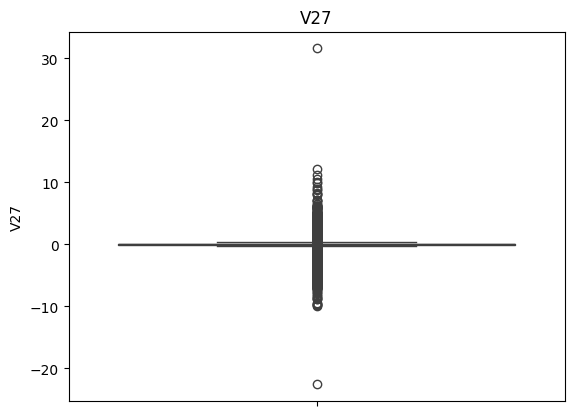

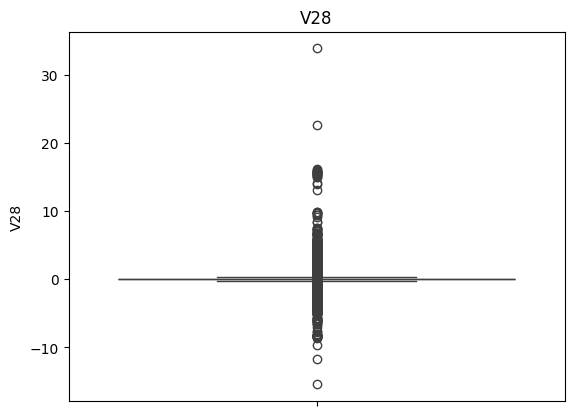

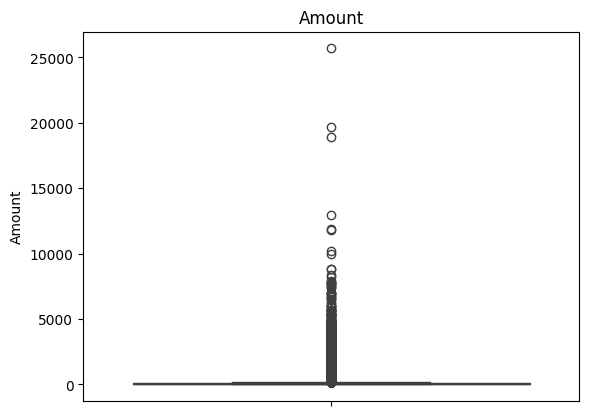

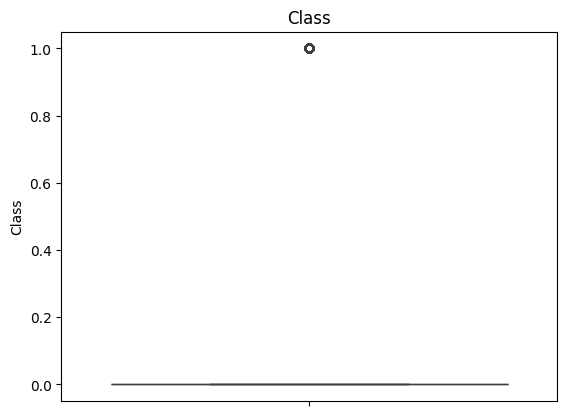

In [17]:
for i in df.columns:
  if df[i].dtype !='object':

    sns.boxplot(df[i])
    plt.title(i)
    plt.show()

/tmp/ipykernel_725/1423816509.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


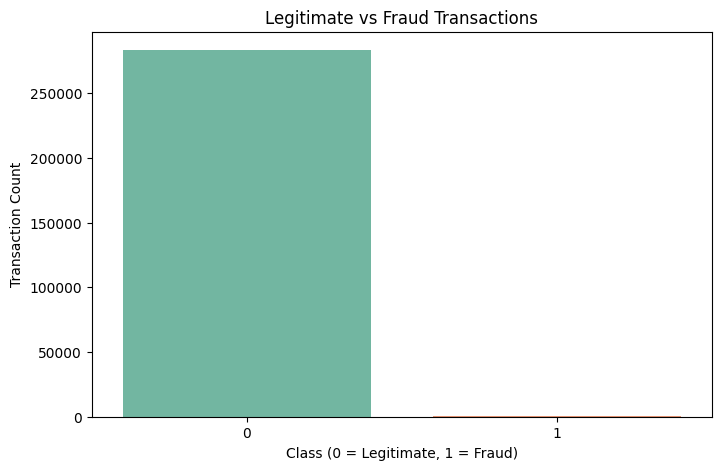

In [18]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Class",
    palette='Set2'
)

plt.title("Legitimate vs Fraud Transactions")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Transaction Count")

plt.show()

In [19]:
fraud_percentage = (
    df["Class"].value_counts(normalize=True) * 100
)

print(fraud_percentage)

Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64


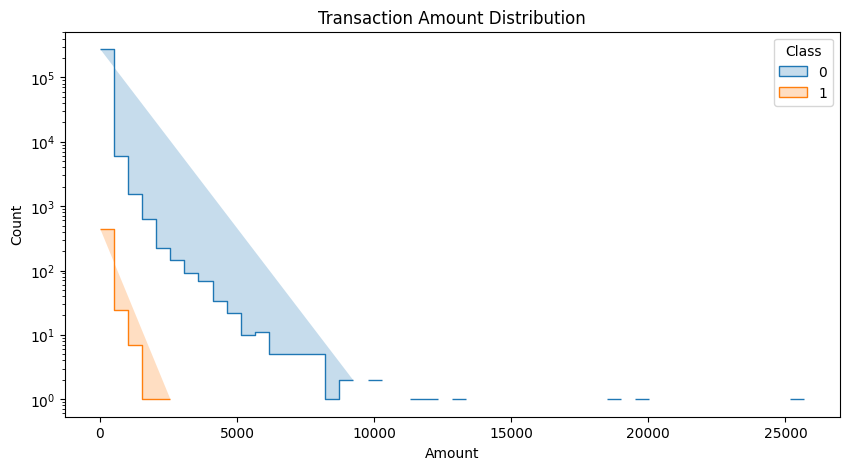

In [20]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=50,
    log_scale=(False, True),
    element="step"
)

plt.title("Transaction Amount Distribution")
plt.show()

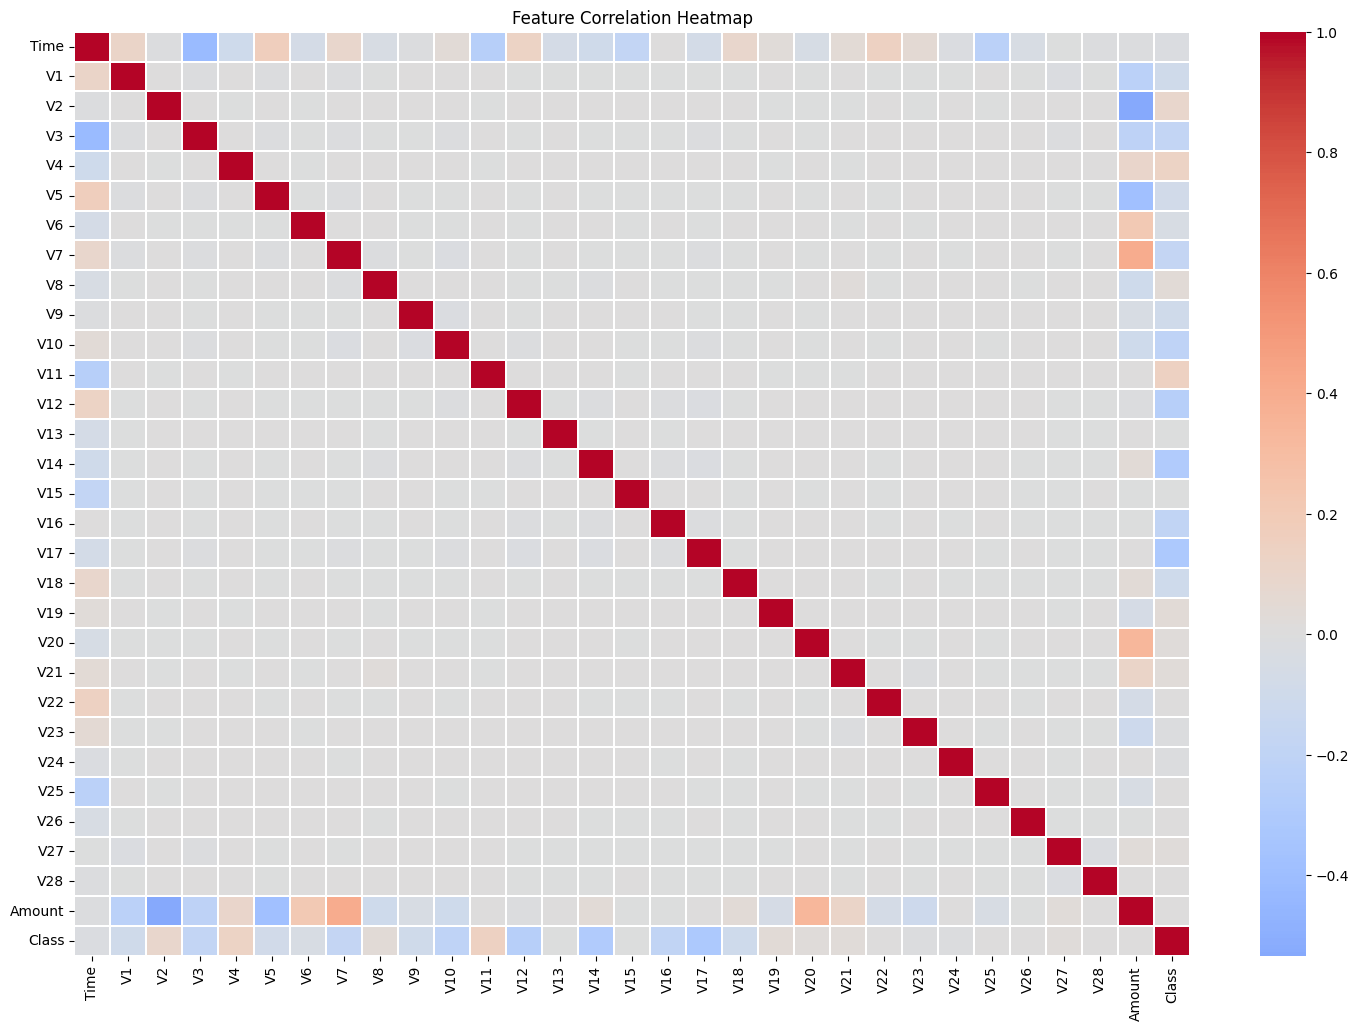

In [21]:
plt.figure(figsize=(18, 12))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    linewidths=0.1
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [22]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


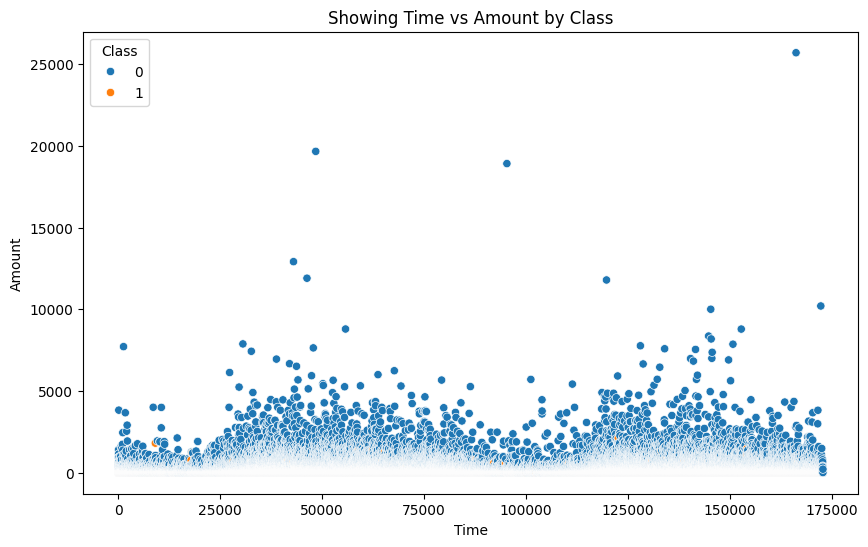

In [23]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Time', y='Amount', hue='Class')
plt.title('Showing Time vs Amount by Class')
plt.show()

In [24]:
display(
    df.groupby("Class")["Amount"]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

,count,mean,median,std,min,max
Class,,,,,,
0,283253,88.413575,22.00,250.379023,0.0,25691.16
1,473,123.871860,9.82,260.211041,0.0,2125.87


In [25]:
df["Amount_log"] = np.log1p(df["Amount"])

df[["Amount", "Amount_log"]].head()

,Amount,Amount_log
0,149.62,5.014760
1,2.69,1.305626
2,378.66,5.939276
3,123.50,4.824306
4,69.99,4.262539


In [26]:
feature_columns = [
    "Time",
    *[f"V{i}" for i in range(1, 29)],
    "Amount_log"
]

target_column = "Class"

x = df[feature_columns].copy()
y = df[target_column].copy()

print("Feature shape:", x.shape)
print("Target shape:", y.shape)

Feature shape: (283726, 30)
Target shape: (283726,)


In [27]:
from sklearn.model_selection import train_test_split

In [28]:
RANDOM_STATE = 42

X_train, X_temp, y_train, y_temp = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nFraud counts:")
print("Train:", y_train.sum())
print("Validation:", y_val.sum())
print("Test:", y_test.sum())

Training: (226980, 30)
Validation: (28373, 30)
Testing: (28373, 30)

Fraud counts:
Train: 378
Validation: 48
Test: 47


In [29]:
negative_count =(y_train ==0).sum()
positive_count = (y_train ==1).sum()

scale_pos_weight =negative_count /positive_count

print('Legitimate:',negative_count)
print('Fraud:',positive_count)
print("Scale pos weight:",scale_pos_weight)

Legitimate: 226602
Fraud: 378
Scale pos weight: 599.4761904761905


In [30]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import (classification_report,confusion_matrix,precision_score,recall_score,f1_score,fbeta_score,average_precision_score,roc_auc_score,precision_recall_curve,roc_curve)

In [31]:
from sklearn.pipeline import Pipeline

lr_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE))
])

lr_model.fit(X_train, y_train)
y_pred = lr_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100)

Accuracy: 0.9738131322031509
Accuracy Percentage: 97.38131322031509


In [32]:
rf_model =RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight='balanced_subsample',
    n_jobs=-1,
    random_state=RANDOM_STATE
)
rf_model.fit(X_train,y_train)
y_pred = rf_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100)

Accuracy: 0.9995770627004547
Accuracy Percentage: 99.95770627004546


In [33]:
xgb_model =XGBClassifier(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.08,
    colsample_bytree=0.08,
    scale_pos_weight=scale_pos_weight,
    eval_metric='aucpr',
    tree_method='hist',
    n_jobs=-1,
    random_state=RANDOM_STATE

)
xgb_model.fit(X_train,y_train)
y_pred = xgb_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100)

Accuracy: 0.9994713283755683
Accuracy Percentage: 99.94713283755684


In [34]:
models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

comparison = []

for name, model in models.items():

    probabilities = model.predict_proba(X_val)[:, 1]

    predictions = (probabilities >= 0.5).astype(int)

    comparison.append({
        "Model": name,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "PR-AUC": average_precision_score(
            y_val, probabilities
        ),
        "ROC-AUC": roc_auc_score(
            y_val, probabilities
        )
    })

comparison_df = pd.DataFrame(comparison)

display(
    comparison_df.sort_values(
        by="PR-AUC",
        ascending=False
    )
)

,Model,Precision,Recall,F1 Score,PR-AUC,ROC-AUC
1,Random Forest,0.942857,0.687500,0.795181,0.791509,0.972324
2,XGBoost,0.871795,0.708333,0.781609,0.769379,0.951698
0,Logistic Regression,0.055866,0.833333,0.104712,0.668006,0.942553


In [35]:
best_model_name = comparison_df.sort_values(
    'PR-AUC',
    ascending=False
).iloc[0]['Model']

best_model = models[best_model_name]

val_probabilities = best_model.predict_proba(X_val)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_val,
    val_probabilities
)

# Fixed variable name and slicing typos:
# - Changed fr_scores to f2_scores
# - Changed precision[:1] to precision[:-1]
# - Changed recall[+-1] to recall[:-1]
f2_scores = (
    5 * precision[:-1] * recall[:-1]
    /
    (4 * precision[:-1] + recall[:-1] + 1e-12)
)

best_index = np.argmax(f2_scores)
best_threshold = thresholds[best_index]

print("Selected model:", best_model_name)
print("Optimal validation threshold:", best_threshold)
print("Validation F2:", f2_scores[best_index])

Selected model: Random Forest
Optimal validation threshold: 0.08655127126209526
Validation F2: 0.7949790794977104


In [36]:
test_probabilities =best_model.predict_proba(X_test)[:,1]

test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

print("FINAL MODEL:",best_model_name)

print("\n Clssification Repost")

print(classification_report(y_test,test_predictions,target_names=["Legitimate","Fraud"],zero_division=0))

print("PR-ACU:",
      average_precision_score(y_test,test_probabilities))

print("ROC-AUC:",
      roc_auc_score(y_test, test_probabilities))

print("F2 Score:",
      fbeta_score(y_test, test_predictions, beta=2))


FINAL MODEL: Random Forest

 Clssification Repost
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     28326
       Fraud       0.76      0.83      0.80        47

    accuracy                           1.00     28373
   macro avg       0.88      0.91      0.90     28373
weighted avg       1.00      1.00      1.00     28373

PR-ACU: 0.8339925615031187
ROC-AUC: 0.9646321475946465
F2 Score: 0.8158995815899581


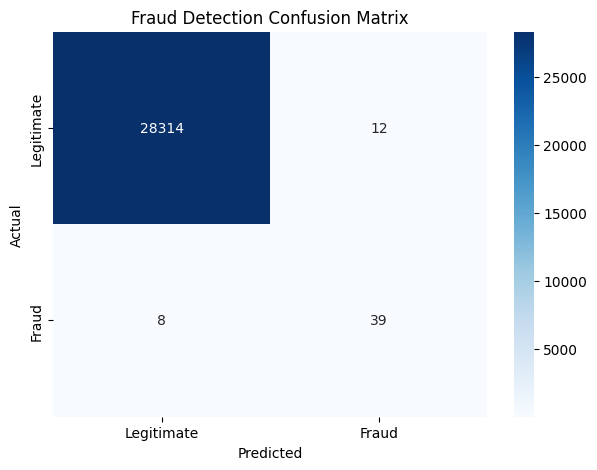

In [37]:
cm=confusion_matrix(y_test,test_predictions)
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Fraud Detection Confusion Matrix")

plt.show()

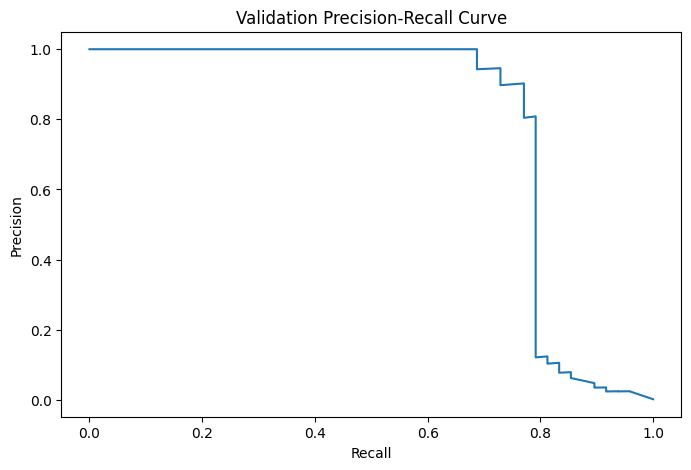

In [38]:
plt.figure(figsize=(8, 5))

plt.plot(recall, precision)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Validation Precision-Recall Curve")

plt.show()

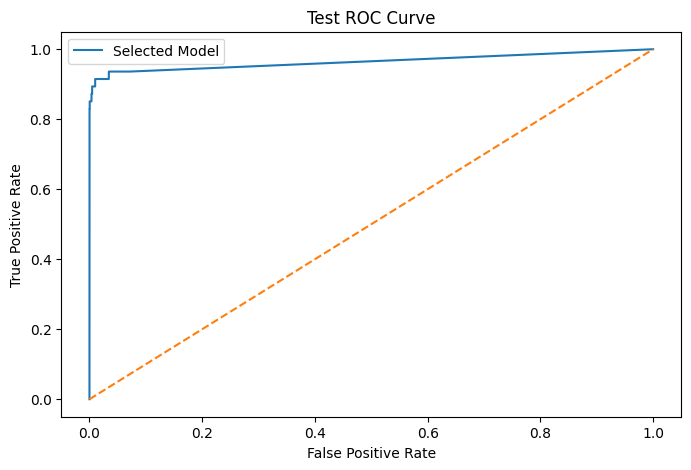

In [39]:
fpr, tpr, roc_thresholds = roc_curve(
    y_test,
    test_probabilities
)

plt.figure(figsize=(8, 5))

plt.plot(fpr, tpr, label="Selected Model")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Test ROC Curve")
plt.legend()

plt.show()

In [40]:
import shap

if best_model_name == "XGBoost":

    explainer = shap.TreeExplainer(best_model)

    shap_values = explainer(
        X_test.sample(
            min(1000, len(X_test)),
            random_state=RANDOM_STATE
        )
    )

    shap.plots.beeswarm(shap_values)

In [41]:
!pip install -q streamlit plotly joblib scikit-learn xgboost

In [42]:
artifact = {
    "model": best_model,
    "feature_columns": feature_columns,
    "threshold": float(best_threshold),
    "model_name": best_model_name,
    "target_column": target_column,
    "amount_transformation": "log1p"
}

os.makedirs("artifacts", exist_ok=True)

joblib.dump(
    artifact,
    "artifacts/fraud_detection_model.joblib"
)

print("Model saved successfully!")

Model saved successfully!


In [43]:
from google.colab import files

files.download(
    "artifacts/fraud_detection_model.joblib"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [78]:
# FraudGuard AI — Advanced Financial Fraud Detection Dashboard
# Run: streamlit run app.py
# Expected model artifact: /content/artifacts/fraud_detection_model.joblib
#
# Artifact format:
# {
#   "model": fitted_classifier_with_predict_proba,
#   "feature_columns": [...],
#   "threshold": 0.5,
#   "model_name": "..."
# }
%%writefile /content/app.py

import io
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import streamlit as st
from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score,
)

# ----------------------------- PAGE CONFIG -----------------------------
st.set_page_config(
    page_title="FraudGuard AI | Financial Intelligence",
    page_icon="🛡️",
    layout="wide",
    initial_sidebar_state="expanded",
)

MODEL_PATH = Path("/content/artifacts/fraud_detection_model.joblib")
FRAUD = "#FFFFFF"
LEGIT = "#16B887"
BLUE = "#FFFFFF"
PURPLE = "#9B7AE8"
AMBER = "#F5A623"
CYAN = "#35BFEA"

# ----------------------------- THEME -----------------------------
if "theme_choice" not in st.session_state:
    st.session_state.theme_choice = "Dark"

theme = st.sidebar.radio(
    "Appearance",
    ["Dark", "Light"],
    key="theme_choice",
    horizontal=True,
)

if theme == "Dark":
    C = {
        "bg": "#0B1020",
        "panel": "#121A2D",
        "panel2": "#18233A",
        "text": "#F3F6FC",
        "muted": "#A4B1C8",
        "border": "#26344E",
        "sidebar": "#090E1B",
        "grid": "#26344E",
        "plot": "#121A2D",
    }
    plot_template = "plotly_dark"
else:
    C = {
        "bg": "#F3F6FC",
        "panel": "#FFFFFF",
        "panel2": "#EAF0FA",
        "text": "#15213B",
        "muted": "#65738B",
        "border": "#DCE4F0",
        "sidebar": "#14213D",
        "grid": "#E1E8F2",
        "plot": "#FFFFFF",
    }
    plot_template = "plotly_white"

st.markdown(
    f"""
    <style>
    .stApp {{ background: {C['bg']}; color: {C['text']}; }}
    [data-testid="stHeader"] {{ background: transparent; }}
    [data-testid="stSidebar"] {{ background: {C['sidebar']}; }}
    [data-testid="stSidebar"] * {{ color: #F5F7FC; }}
    .block-container {{ padding-top: 1.6rem; padding-bottom: 2.5rem; }}
    h1, h2, h3, h4, p, label {{ color: {C['text']}; }}
    .hero {{
        padding: 24px 28px; border-radius: 18px; margin-bottom: 18px;
        background: linear-gradient(115deg, #172B50 0%, #263C70 52%, #412D72 100%);
        border: 1px solid #435785;
    }}
    .hero-title {{ color: #FFFFFF; font-size: 32px; font-weight: 850; letter-spacing: -0.7px; }}
    .hero-sub {{ color: #D5E2FF; font-size: 14px; margin-top: 5px; }}
    .eyebrow {{ color: #8FC8FF; font-size: 11px; font-weight: 800; letter-spacing: 2px; }}
    .metric {{
        background: {C['panel']}; border: 1px solid {C['border']};
        border-radius: 15px; padding: 17px 18px; min-height: 112px;
        box-shadow: 0 5px 18px rgba(0,0,0,0.08);
    }}
    .metric-label {{ color: {C['muted']}; font-size: 12px; font-weight: 700; text-transform: uppercase; letter-spacing: .7px; }}
    .metric-value {{ font-size: 27px; font-weight: 850; margin-top: 8px; color: {C['text']}; }}
    .metric-note {{ color: {C['muted']}; font-size: 11px; margin-top: 4px; }}
    .section-note {{
        background: {C['panel2']}; border-left: 4px solid {BLUE};
        padding: 12px 15px; border-radius: 8px; color: {C['text']};
        font-size: 13px; margin: 4px 0 14px 0;
    }}
    .risk-pill {{ display:inline-block; border-radius:30px; padding:5px 11px; font-size:11px; font-weight:800; }}
    div[data-testid="stForm"], div[data-testid="stDataFrame"] {{
        border: 1px solid {C['border']}; border-radius: 12px;
    }}
    .stButton button, .stDownloadButton button {{
        border-radius: 10px; font-weight: 700;
    }}
    </style>
    """,
    unsafe_allow_html=True,
)

# ----------------------------- HELPERS -----------------------------
def money(value):
    if pd.isna(value):
        return "N/A"
    return f"{value:,.2f}"

def metric_card(label, value, color=BLUE, note=""):
    st.markdown(
        f"""
        <div class="metric">
            <div class="metric-label">{label}</div>
            <div class="metric-value" style="color:{color}">{value}</div>
            <div class="metric-note">{note}</div>
        </div>
        """,
        unsafe_allow_html=True,
    )

def style_fig(fig, height=360):
    fig.update_layout(
        template=plot_template,
        height=height,
        paper_bgcolor=C["plot"],
        plot_bgcolor=C["plot"],
        font=dict(family="Inter, Arial", color=C["text"], size=12),
        title=dict(font=dict(size=16, color=C["text"])),
        legend_title_text="",
        margin=dict(l=18, r=18, t=58, b=18),
        hoverlabel=dict(bgcolor=C["panel"], font_color=C["text"]),
    )
    fig.update_xaxes(showgrid=True, gridcolor=C["grid"], zeroline=False)
    fig.update_yaxes(showgrid=True, gridcolor=C["grid"], zeroline=False)
    return fig

def fraud_gauge(probability, title="Estimated fraud probability"):
    """Display one transaction's estimated fraud probability as a 0–100% gauge."""
    value = float(np.clip(probability, 0, 1)) * 100
    gauge = go.Figure(
        go.Indicator(
            mode="gauge+number",
            value=value,
            number={"suffix": "%", "font": {"size": 30, "color": C["text"]}},
            title={"text": title, "font": {"size": 15, "color": C["text"]}},
            gauge={
                "axis": {"range": [0, 100], "ticksuffix": "%"},
                "bar": {"color": FRAUD if value >= threshold else LEGIT},
                "bgcolor": C["panel2"],
                "bordercolor": C["border"],
                "steps": [
                    {"range": [0, 40], "color": "rgba(22,184,135,0.20)"},
                    {"range": [40, 70], "color": "rgba(245,166,35,0.22)"},
                    {"range": [70, 90], "color": "rgba(240,120,53,0.22)"},
                    {"range": [90, 100], "color": "rgba(240,68,94,0.22)"},
                ],
                "threshold": {
                    "line": {"color": AMBER, "width": 4},
                    "thickness": 0.8,
                    "value": threshold * 100,
                },
            },
        )
    )
    return style_fig(gauge, 280)

def explain(text):
    st.markdown(f'<div class="section-note">💡 {text}</div>', unsafe_allow_html=True)

def risk_category(probability):
    if probability >= 0.90:
        return "Critical"
    if probability >= 0.70:
        return "High"
    if probability >= 0.40:
        return "Medium"
    return "Low"

def prepare_predictions(data, model, feature_columns, threshold):
    """Validate input, create Amount_log when needed, and score transactions."""
    if data is None or data.empty:
        raise ValueError("The uploaded dataset contains no transaction rows.")

    df = data.copy()
    if "Time" not in df.columns or "Amount" not in df.columns:
        raise ValueError("CSV must contain both 'Time' and 'Amount' columns.")

    df["Time"] = pd.to_numeric(df["Time"], errors="coerce")
    df["Amount"] = pd.to_numeric(df["Amount"], errors="coerce")
    if df[["Time", "Amount"]].isna().any().any():
        raise ValueError("'Time' and 'Amount' must contain valid numeric values.")
    if (df[["Time", "Amount"]] < 0).any().any():
        raise ValueError("'Time' and 'Amount' cannot be negative.")

    if "Amount_log" not in df.columns:
        df["Amount_log"] = np.log1p(df["Amount"])

    missing = [col for col in feature_columns if col not in df.columns]
    if missing:
        raise ValueError(f"Missing model features: {missing}")

    X = df[feature_columns].apply(pd.to_numeric, errors="coerce")
    if X.isna().any().any():
        bad = X.columns[X.isna().any()].tolist()
        raise ValueError(f"Missing or non-numeric values in model features: {bad}")
    if not np.isfinite(X.to_numpy(dtype=float)).all():
        raise ValueError("Model features contain infinite or invalid numeric values.")

    if not hasattr(model, "predict_proba"):
        raise ValueError("The saved model must support predict_proba().")

    probabilities = model.predict_proba(X)[:, 1]
    result = df.copy()
    result["Fraud Probability"] = probabilities
    result["Prediction"] = np.where(probabilities >= threshold, "Fraud", "Legitimate")
    result["Risk Category"] = [risk_category(p) for p in probabilities]
    result["Risk Score"] = (probabilities * 100).round(2)
    result["Transaction ID"] = np.arange(1, len(result) + 1)
    return result

def add_time_bucket(df):
    """Create elapsed-hour buckets; Time is not assumed to be a real clock time."""
    out = df.copy()
    out["Elapsed Hour"] = (out["Time"] // 3600).astype(int)
    return out

def filtered_data(df):
    st.markdown("#### Filter transactions")
    a, b, c = st.columns(3)
    with a:
        status = st.multiselect(
            "Prediction status",
            ["Fraud", "Legitimate"],
            default=["Fraud", "Legitimate"],
        )
    with b:
        risks = st.multiselect(
            "Risk category",
            ["Critical", "High", "Medium", "Low"],
            default=["Critical", "High", "Medium", "Low"],
        )
    with c:
        max_amount = float(df["Amount"].max()) if len(df) else 0.0
        min_amount = float(df["Amount"].min()) if len(df) else 0.0
        if max_amount > min_amount:
            amount_range = st.slider(
                "Amount range",
                min_value=min_amount,
                max_value=max_amount,
                value=(min_amount, max_amount),
            )
        else:
            amount_range = (min_amount, max_amount)

    result = df[
        df["Prediction"].isin(status)
        & df["Risk Category"].isin(risks)
        & df["Amount"].between(amount_range[0], amount_range[1])
    ]
    st.caption(f"Showing {len(result):,} of {len(df):,} transactions.")
    return result

def show_download(df, filename="fraudguard_report.csv"):
    st.download_button(
        "⬇️ Download results as CSV",
        data=df.to_csv(index=False).encode("utf-8"),
        file_name=filename,
        mime="text/csv",
        use_container_width=False,
    )

# ----------------------------- MODEL LOAD -----------------------------
@st.cache_resource
def load_artifact(path_string):
    return joblib.load(path_string)

if not MODEL_PATH.exists():
    st.error(
        f"Model artifact not found: `{MODEL_PATH}`. "
        "Run the model-training notebook cell that saves fraud_detection_model.joblib."
    )
    st.stop()

try:
    artifact = load_artifact(str(MODEL_PATH))
    model = artifact["model"]
    feature_columns = artifact["feature_columns"]
    threshold = float(artifact["threshold"])
    model_name = artifact.get("model_name", type(model).__name__)
    if not 0 <= threshold <= 1:
        raise ValueError("The saved threshold must be between 0 and 1.")
except Exception as exc:
    st.error(f"Could not load model artifact: {exc}")
    st.stop()

# ----------------------------- SIDEBAR -----------------------------
with st.sidebar:
    st.markdown("## 🛡️ FraudGuard AI")
    st.caption("FINANCIAL RISK INTELLIGENCE")
    st.markdown("---")
    page = st.radio(
        "NAVIGATION",
        [
            "Executive Dashboard",
            "Single Prediction",
            "Batch Prediction",
            "Advanced Analytics",
            "Model Insights",
        ],
    )
    st.markdown("---")
    st.markdown("### Model status")
    st.success("Model loaded successfully")
    st.write(f"**Model:** {model_name}")
    st.write(f"**Threshold:** {threshold:.4f}")
    st.write(f"**Features:** {len(feature_columns)}")
    st.markdown("---")
    st.markdown("### Shared transaction data")
    uploaded_csv = st.file_uploader(
        "Upload transaction CSV",
        type=["csv"],
        key="fraudguard_csv",
        help="The uploaded dataset is shared across dashboard pages.",
    )
    if uploaded_csv is not None:
        try:
            st.session_state["fraudguard_raw"] = pd.read_csv(uploaded_csv)
            st.session_state["fraudguard_filename"] = uploaded_csv.name
            st.session_state.pop("fraudguard_error", None)
        except Exception as exc:
            st.session_state["fraudguard_error"] = str(exc)

    if "fraudguard_raw" in st.session_state:
        st.caption(f"Loaded: {st.session_state.get('fraudguard_filename', 'CSV')}")
        if st.button("Clear dataset", use_container_width=True):
            for key in [
                "fraudguard_raw",
                "fraudguard_filename",
                "fraudguard_results",
                "fraudguard_error",
            ]:
                st.session_state.pop(key, None)
            st.rerun()

# ----------------------------- SCORE SHARED DATA -----------------------------
raw_df = st.session_state.get("fraudguard_raw")
results = None
data_error = st.session_state.get("fraudguard_error")

if raw_df is not None and not data_error:
    try:
        results = prepare_predictions(raw_df, model, feature_columns, threshold)
        st.session_state["fraudguard_results"] = results
    except Exception as exc:
        data_error = str(exc)

# ----------------------------- APP HEADER -----------------------------
st.markdown(
    """
    <div class="hero">
      <div class="eyebrow">AI • MACHINE LEARNING • FINANCIAL SECURITY</div>
      <div class="hero-title">🛡️ FraudGuard AI</div>
      <div class="hero-sub">Intelligent transaction monitoring · Risk scoring · Fraud analytics</div>
    </div>
    """,
    unsafe_allow_html=True,
)

if data_error:
    st.error(f"Dataset processing error: {data_error}")
    st.info("Check the required columns and values, then upload a corrected CSV.")

# ----------------------------- EXECUTIVE DASHBOARD -----------------------------
if page == "Executive Dashboard":
    st.subheader("📊 Executive Overview")
    if results is None:
        st.info("Upload your transaction CSV from the sidebar to activate the dashboard.")
        st.markdown("**Expected input:** `Time`, `Amount`, and all saved model feature columns.")
    else:
        total = len(results)
        fraud_count = int((results["Prediction"] == "Fraud").sum())
        legit_count = total - fraud_count
        fraud_rate = fraud_count / total * 100 if total else 0
        critical_count = int((results["Risk Category"] == "Critical").sum())
        fraud_amount = results.loc[results["Prediction"] == "Fraud", "Amount"].sum()

        k = st.columns(5)
        with k[0]:
            metric_card("Transactions", f"{total:,}", BLUE, "Total scored rows")
        with k[1]:
            metric_card("Fraud detected", f"{fraud_count:,}", FRAUD, "Predicted fraud")
        with k[2]:
            metric_card("Legitimate", f"{legit_count:,}", LEGIT, "Predicted legitimate")
        with k[3]:
            metric_card("Fraud rate", f"{fraud_rate:.2f}%", AMBER, "Share of scored rows")
        with k[4]:
            metric_card("Critical risk", f"{critical_count:,}", PURPLE, "Probability ≥ 90%")

        st.markdown("")
        left, right = st.columns([1, 1.35])
        with left:
            pie = px.pie(
                names=["Legitimate", "Fraud"],
                values=[legit_count, fraud_count],
                hole=0.68,
                title="Transaction distribution",
                color_discrete_map={"Legitimate": LEGIT, "Fraud": FRAUD},
            )
            pie.update_traces(
                textinfo="percent+label",
                hovertemplate="%{label}<br>Count: %{value:,}<br>Share: %{percent}<extra></extra>",
                marker=dict(line=dict(color=C["plot"], width=3)),
            )
            pie.add_annotation(
                text=f"<b>{total:,}</b><br><sup>Transactions</sup>",
                showarrow=False,
                font=dict(size=17, color=C["text"]),
            )
            st.plotly_chart(style_fig(pie, 350), use_container_width=True)
            explain("The donut chart shows the share of transactions classified as fraud or legitimate using the model's saved decision threshold.")
        with right:
            hist = px.histogram(
                results,
                x="Fraud Probability",
                color="Prediction",
                nbins=35,
                barmode="overlay",
                opacity=0.78,
                title="Fraud probability distribution",
                color_discrete_map={"Fraud": FRAUD, "Legitimate": LEGIT},
            )
            hist.add_vline(
                x=threshold,
                line_dash="dash",
                line_color=AMBER,
                annotation_text=f"Threshold {threshold:.2f}",
            )
            st.plotly_chart(style_fig(hist, 350), use_container_width=True)
            explain("Each bar counts transactions within a probability interval. Values to the right of the dashed threshold are classified as fraud.")

        # Fraud Risk Gauge: average probability across all uploaded transactions.
        avg_probability = float(results["Fraud Probability"].mean())
        gauge_col, note_col = st.columns([1, 1.35])
        with gauge_col:
            st.plotly_chart(
                fraud_gauge(avg_probability, "Average estimated fraud probability"),
                use_container_width=True,
            )
        with note_col:
            st.markdown("### 🎯 Fraud Risk Gauge")
            st.metric("Average model-estimated fraud probability", f"{avg_probability:.2%}")
            st.write(
                "This gauge summarizes the average fraud probability across the uploaded "
                "transactions. It is a model score, not the percentage of transactions "
                "confirmed to be fraudulent. The amber marker shows the saved decision threshold."
            )
            explain("A higher probability indicates a higher estimated risk. The saved threshold determines whether an individual transaction is labeled Fraud.")

        st.markdown("### 🚨 Transactions requiring attention")
        high_risk = results[results["Risk Category"].isin(["Critical", "High"])].sort_values(
            "Fraud Probability", ascending=False
        )
        if high_risk.empty:
            st.success("No transactions currently fall into the High or Critical probability bands.")
        else:
            st.dataframe(
                high_risk[
                    ["Transaction ID", "Amount", "Fraud Probability", "Risk Category", "Prediction"]
                ].head(10),
                use_container_width=True,
                hide_index=True,
            )
        st.caption(f"Predicted fraud transaction amount total: {money(fraud_amount)} (dataset currency units).")

        with st.expander("How to interpret this dashboard"):
            st.write(
                "- **Fraud rate** is the percentage of uploaded rows predicted as fraud; it is not a verified real-world fraud rate.\n"
                "- **Critical risk** means model probability of at least 90%; this is a display band, not a regulatory standard.\n"
                "- **Predicted fraud amount** is the sum of Amount for rows predicted as fraud, not confirmed financial loss."
            )

# ----------------------------- SINGLE PREDICTION -----------------------------
elif page == "Single Prediction":
    st.subheader("🔍 Single Transaction Risk Assessment")
    if results is not None:
        st.write("Choose a row from the uploaded dataset.")
        row_no = st.number_input(
            "Transaction row number",
            min_value=1,
            max_value=len(results),
            value=1,
            step=1,
        )
        selected = results.iloc[[int(row_no) - 1]]
        p = float(selected["Fraud Probability"].iloc[0])
        prediction = selected["Prediction"].iloc[0]
        risk = selected["Risk Category"].iloc[0]
        st.dataframe(selected, use_container_width=True, hide_index=True)
        a, b, c = st.columns(3)
        with a:
            metric_card("Fraud probability", f"{p:.2%}", FRAUD if p >= threshold else LEGIT)
        with b:
            metric_card("Decision threshold", f"{threshold:.2%}", AMBER)
        with c:
            metric_card("Risk category", risk, PURPLE)
        st.progress(min(max(p, 0.0), 1.0))
        st.plotly_chart(
            fraud_gauge(p, "Selected transaction fraud probability"),
            use_container_width=True,
        )
        if prediction == "Fraud":
            st.error("🚨 Model decision: FRAUD — review this transaction.")
        else:
            st.success("✅ Model decision: LEGITIMATE — the score is below the saved threshold.")
        explain("Fraud probability is the model's estimated score. The threshold converts that score into a class; it is not a guarantee.")
    else:
        st.info("Upload a transaction CSV to select a transaction, or enter feature values manually.")
        st.warning("Manual values must use the same feature definitions and preprocessing as the model-training pipeline.")
        with st.form("manual_prediction_form"):
            base1, base2 = st.columns(2)
            with base1:
                time_value = st.number_input("Time", min_value=0.0, value=0.0)
            with base2:
                amount = st.number_input("Amount", min_value=0.0, value=100.0)
            values = {}
            st.markdown("#### Model input features")
            feature_cols = st.columns(3)
            for idx, feature in enumerate(feature_columns):
                with feature_cols[idx % 3]:
                    if feature == "Time":
                        values[feature] = time_value
                    elif feature == "Amount":
                        values[feature] = amount
                    elif feature == "Amount_log":
                        values[feature] = np.log1p(amount)
                    else:
                        values[feature] = st.number_input(
                            feature, value=0.0, format="%.6f", key=f"manual_{feature}"
                        )
            submitted = st.form_submit_button("🔎 Score transaction", use_container_width=True)
        if submitted:
            try:
                manual_row = {"Time": time_value, "Amount": amount, **values}
                scored = prepare_predictions(
                    pd.DataFrame([manual_row]), model, feature_columns, threshold
                )
                p = float(scored["Fraud Probability"].iloc[0])
                if scored["Prediction"].iloc[0] == "Fraud":
                    st.error("🚨 FRAUD RISK FLAGGED")
                else:
                    st.success("✅ BELOW FRAUD DECISION THRESHOLD")
                x, y = st.columns(2)
                with x:
                    metric_card("Fraud probability", f"{p:.2%}", FRAUD)
                with y:
                    metric_card("Decision threshold", f"{threshold:.2%}", AMBER)
                st.progress(min(max(p, 0.0), 1.0))
                st.plotly_chart(
                    fraud_gauge(p, "Manual transaction fraud probability"),
                    use_container_width=True,
                )
                st.dataframe(scored, use_container_width=True, hide_index=True)
            except Exception as exc:
                st.error(str(exc))

# ----------------------------- BATCH PREDICTION -----------------------------
elif page == "Batch Prediction":
    st.subheader("📦 Batch Transaction Scoring")
    if results is None:
        st.info("Upload a CSV from the sidebar to score a batch of transactions.")
    else:
        st.write("All uploaded rows have been scored by the saved model.")
        subset = filtered_data(results)
        fraud_n = int((subset["Prediction"] == "Fraud").sum())
        legit_n = len(subset) - fraud_n
        a, b, c = st.columns(3)
        with a:
            metric_card("Filtered rows", f"{len(subset):,}", BLUE)
        with b:
            metric_card("Fraud rows", f"{fraud_n:,}", FRAUD)
        with c:
            metric_card("Legitimate rows", f"{legit_n:,}", LEGIT)
        st.dataframe(subset, use_container_width=True, hide_index=True)
        show_download(subset)
        explain("Use the filters to focus on specific prediction classes, risk levels, or transaction amount ranges. Download exports only the filtered rows.")

# ----------------------------- ADVANCED ANALYTICS -----------------------------
elif page == "Advanced Analytics":
    st.subheader("📈 Advanced Fraud Analytics")
    if results is None:
        st.info("Upload a valid transaction CSV to view analytics.")
    else:
        analytics = filtered_data(results)
        if analytics.empty:
            st.warning("No transactions match the selected filters.")
        else:
            # Amount distribution
            left, right = st.columns(2)
            with left:
                amount_fig = px.histogram(
                    analytics,
                    x="Amount",
                    color="Prediction",
                    nbins=40,
                    marginal="box",
                    title="Transaction amount distribution",
                    color_discrete_map={"Fraud": FRAUD, "Legitimate": LEGIT},
                    opacity=0.8,
                )
                st.plotly_chart(style_fig(amount_fig, 390), use_container_width=True)
                explain("This plot compares transaction amounts across model-predicted classes. A box plot helps reveal spread and unusually large values.")
            with right:
                box_fig = px.box(
                    analytics,
                    x="Prediction",
                    y="Amount",
                    color="Prediction",
                    points="outliers",
                    title="Amount spread by prediction",
                    color_discrete_map={"Fraud": FRAUD, "Legitimate": LEGIT},
                )
                st.plotly_chart(style_fig(box_fig, 390), use_container_width=True)
                explain("The box shows the median and middle 50% of amounts. Points beyond the whiskers are potential statistical outliers, not automatically fraud.")

            # Risk bands
            risk_order = ["Low", "Medium", "High", "Critical"]
            risk_counts = (
                analytics["Risk Category"]
                .value_counts()
                .reindex(risk_order, fill_value=0)
                .rename_axis("Risk Category")
                .reset_index(name="Transactions")
            )
            left, right = st.columns(2)
            with left:
                risk_fig = px.bar(
                    risk_counts,
                    x="Risk Category",
                    y="Transactions",
                    color="Risk Category",
                    category_orders={"Risk Category": risk_order},
                    color_discrete_map={
                        "Low": LEGIT,
                        "Medium": AMBER,
                        "High": "#F07835",
                        "Critical": FRAUD,
                    },
                    title="Transaction risk segmentation",
                    text_auto=True,
                )
                st.plotly_chart(style_fig(risk_fig, 350), use_container_width=True)
                explain("Risk bands are probability groupings used to prioritize review: Low < 40%, Medium 40–70%, High 70–90%, Critical ≥ 90%.")
            with right:
                scatter = px.scatter(
                    analytics,
                    x="Amount",
                    y="Fraud Probability",
                    color="Prediction",
                    size="Risk Score",
                    hover_data=["Transaction ID", "Risk Category"],
                    title="Transaction amount vs fraud probability",
                    color_discrete_map={"Fraud": FRAUD, "Legitimate": LEGIT},
                    opacity=0.72,
                )
                scatter.add_hline(y=threshold, line_dash="dash", line_color=AMBER)
                st.plotly_chart(style_fig(scatter, 350), use_container_width=True)
                explain("Each dot is a transaction. The horizontal line is the decision threshold; points above it are classified as fraud.")

            # Time analytics
            time_df = add_time_bucket(analytics)
            timeline = (
                time_df.groupby(["Elapsed Hour", "Prediction"])
                .size()
                .reset_index(name="Transactions")
            )
            timeline_fig = px.line(
                timeline,
                x="Elapsed Hour",
                y="Transactions",
                color="Prediction",
                markers=True,
                title="Transactions across elapsed-time buckets",
                color_discrete_map={"Fraud": FRAUD, "Legitimate": LEGIT},
            )
            st.plotly_chart(style_fig(timeline_fig, 370), use_container_width=True)
            explain("The Time column in common credit-card datasets is elapsed seconds from a reference point. This chart groups it into elapsed-hour buckets; it does not represent actual time of day.")

            # Probability density
            prob_fig = px.histogram(
                analytics,
                x="Fraud Probability",
                color="Prediction",
                histnorm="probability density",
                nbins=35,
                barmode="overlay",
                opacity=0.65,
                title="Fraud probability density",
                color_discrete_map={"Fraud": FRAUD, "Legitimate": LEGIT},
            )
            prob_fig.add_vline(x=threshold, line_dash="dash", line_color=AMBER)
            st.plotly_chart(style_fig(prob_fig, 350), use_container_width=True)
            explain("Density normalizes the histogram to compare the shape of the probability distributions, rather than raw transaction counts.")

            # ---------------- GROUND-TRUTH MODEL EVALUATION ----------------
            st.markdown("### 🧪 Model Evaluation")
            if "Class" not in raw_df.columns:
                st.info(
                    "The uploaded CSV does not contain a 'Class' column. "
                    "Confusion Matrix, ROC Curve, and Precision–Recall Curve need "
                    "the actual known labels (0 = Legitimate, 1 = Fraud)."
                )
            else:
                actual = pd.to_numeric(raw_df["Class"], errors="coerce")
                valid_labels = actual.notna() & actual.isin([0, 1])
                if not valid_labels.all():
                    st.warning(
                        "Some values in 'Class' are missing or are not 0/1. "
                        "Evaluation charts are calculated only for rows with valid labels."
                    )

                eval_df = results.loc[valid_labels].copy()
                y_true = actual.loc[valid_labels].astype(int).to_numpy()
                y_prob = eval_df["Fraud Probability"].to_numpy()
                y_pred = (y_prob >= threshold).astype(int)

                if len(y_true) == 0:
                    st.warning("No valid actual labels are available for evaluation.")
                else:
                    from sklearn.metrics import (
                        accuracy_score,
                        precision_score,
                        recall_score,
                        f1_score,
                    )

                    e1, e2, e3, e4 = st.columns(4)
                    with e1:
                        metric_card("Accuracy", f"{accuracy_score(y_true, y_pred):.3f}", BLUE)
                    with e2:
                        metric_card(
                            "Precision",
                            f"{precision_score(y_true, y_pred, zero_division=0):.3f}",
                            PURPLE,
                        )
                    with e3:
                        metric_card(
                            "Recall",
                            f"{recall_score(y_true, y_pred, zero_division=0):.3f}",
                            AMBER,
                        )
                    with e4:
                        metric_card(
                            "F1-score",
                            f"{f1_score(y_true, y_pred, zero_division=0):.3f}",
                            LEGIT,
                        )

                    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
                    cm_fig = px.imshow(
                        cm,
                        text_auto=True,
                        x=["Predicted Legitimate", "Predicted Fraud"],
                        y=["Actual Legitimate", "Actual Fraud"],
                        color_continuous_scale="Blues",
                        title="Confusion Matrix",
                        labels={"x": "Predicted label", "y": "Actual label", "color": "Count"},
                    )
                    st.plotly_chart(style_fig(cm_fig, 390), use_container_width=True)
                    explain(
                        "True Negative: legitimate correctly identified. True Positive: fraud correctly "
                        "identified. False Positive: legitimate incorrectly flagged as fraud. "
                        "False Negative: fraud missed by the model."
                    )

                    if len(np.unique(y_true)) == 2:
                        curve_left, curve_right = st.columns(2)
                        with curve_left:
                            fpr, tpr, _ = roc_curve(y_true, y_prob)
                            roc_auc = auc(fpr, tpr)
                            roc_fig = go.Figure()
                            roc_fig.add_trace(
                                go.Scatter(
                                    x=fpr, y=tpr, mode="lines",
                                    name=f"ROC (AUC = {roc_auc:.3f})",
                                    line=dict(color=BLUE, width=3),
                                )
                            )
                            roc_fig.add_trace(
                                go.Scatter(
                                    x=[0, 1], y=[0, 1], mode="lines",
                                    name="Random baseline",
                                    line=dict(color=C["muted"], dash="dash"),
                                )
                            )
                            roc_fig.update_layout(
                                title=f"ROC Curve (AUC = {roc_auc:.3f})",
                                xaxis_title="False Positive Rate",
                                yaxis_title="True Positive Rate",
                            )
                            st.plotly_chart(style_fig(roc_fig, 390), use_container_width=True)
                            explain(
                                "The ROC curve compares the true-positive rate with the false-positive "
                                "rate at different thresholds. A curve closer to the top-left is generally better."
                            )

                        with curve_right:
                            precision_values, recall_values, _ = precision_recall_curve(y_true, y_prob)
                            ap = average_precision_score(y_true, y_prob)
                            pr_fig = go.Figure()
                            pr_fig.add_trace(
                                go.Scatter(
                                    x=recall_values, y=precision_values, mode="lines",
                                    name=f"Precision–Recall (AP = {ap:.3f})",
                                    line=dict(color=PURPLE, width=3),
                                )
                            )
                            pr_fig.update_layout(
                                title=f"Precision–Recall Curve (AP = {ap:.3f})",
                                xaxis_title="Recall",
                                yaxis_title="Precision",
                                xaxis=dict(range=[0, 1]),
                                yaxis=dict(range=[0, 1.05]),
                            )
                            st.plotly_chart(style_fig(pr_fig, 390), use_container_width=True)
                            explain(
                                "This curve shows the trade-off between precision and recall. "
                                "It is especially useful for imbalanced fraud datasets because fraud cases are rare."
                            )
                    else:
                        st.warning(
                            "ROC and Precision–Recall curves require both classes "
                            "(at least one legitimate and one fraud transaction) in the labeled data."
                        )

                    st.caption(
                        f"Evaluation uses {len(y_true):,} rows with valid actual Class labels "
                        "and the model's saved probability threshold."
                    )

            # Correlation heatmap on a safe subset of numeric columns
            with st.expander("Explore numeric feature correlations"):
                numeric = analytics.select_dtypes(include=np.number)
                if len(numeric.columns) >= 2:
                    candidates = [c for c in numeric.columns if c not in ["Transaction ID"]]
                    chosen = st.multiselect(
                        "Choose numeric columns (maximum 18)",
                        candidates,
                        default=candidates[: min(10, len(candidates))],
                    )
                    chosen = chosen[:18]
                    if len(chosen) >= 2:
                        corr = analytics[chosen].corr(numeric_only=True)
                        heat = px.imshow(
                            corr,
                            text_auto=".2f",
                            color_continuous_scale="RdBu_r",
                            zmin=-1,
                            zmax=1,
                            title="Feature correlation heatmap",
                            aspect="auto",
                        )
                        st.plotly_chart(style_fig(heat, 520), use_container_width=True)
                        explain("Correlation ranges from -1 to +1. Values near +1 indicate positive linear association, values near -1 indicate negative association, and values near 0 indicate weak linear association. Correlation does not prove causation.")
                    else:
                        st.caption("Select at least two numeric columns.")
                else:
                    st.info("At least two numeric columns are needed for a correlation heatmap.")

            st.markdown("### Highest-risk transactions")
            top = analytics.sort_values("Fraud Probability", ascending=False).head(10)
            st.dataframe(
                top[["Transaction ID", "Time", "Amount", "Fraud Probability", "Risk Category", "Prediction"]],
                use_container_width=True,
                hide_index=True,
            )
            show_download(analytics, "fraudguard_analytics_filtered.csv")

# ----------------------------- MODEL INSIGHTS -----------------------------
elif page == "Model Insights":
    st.subheader("🧠 Model & Methodology")
    a, b, c = st.columns(3)
    with a:
        metric_card("Model", str(model_name), BLUE, "Loaded from saved artifact")
    with b:
        metric_card("Decision threshold", f"{threshold:.4f}", AMBER, "Saved training threshold")
    with c:
        metric_card("Input features", f"{len(feature_columns)}", PURPLE, "Required model columns")

    st.markdown("### How a transaction is scored")
    st.markdown(
        """
        1. **Input validation** — checks required columns and numeric values.
        2. **Feature preparation** — creates `Amount_log = log1p(Amount)` if the dataset does not already contain it.
        3. **Feature alignment** — selects columns in the exact order saved with the model.
        4. **Probability estimation** — calls the model's `predict_proba()` method.
        5. **Threshold decision** — probability at or above the saved threshold is labeled Fraud.
        6. **Risk grouping** — adds a display category to help prioritize manual review.
        """
    )
    explain("The app uses the preprocessing assumptions in this code. If your training notebook used a scaler, encoder, imputer, or other transformations outside the saved model pipeline, those same transformations must also be saved and applied here.")

    st.markdown("### Model input features")
    st.code(", ".join(map(str, feature_columns)), language="text")

    st.markdown("### Risk category definitions")
    risk_table = pd.DataFrame(
        {
            "Category": ["Low", "Medium", "High", "Critical"],
            "Probability range": ["Below 40%", "40% to below 70%", "70% to below 90%", "90% to 100%"],
            "Suggested handling": [
                "Routine monitoring",
                "Consider additional checks",
                "Prioritize review",
                "Urgent manual review",
            ],
        }
    )
    st.dataframe(risk_table, use_container_width=True, hide_index=True)

    st.markdown("### Important evaluation note")
    st.warning(
        "Predictions are not verified fraud labels. Evaluation charts are calculated only "
        "when the uploaded CSV contains the actual ground-truth Class column (0 = Legitimate, "
        "1 = Fraud). Do not describe predicted fraud rows as confirmed fraud."
    )

    st.markdown("### Dataset status")
    if results is None:
        st.info("No valid dataset has been scored yet.")
    else:
        st.success(f"{len(results):,} transactions scored successfully.")
        st.write(f"Uploaded file: {st.session_state.get('fraudguard_filename', 'CSV')}")
        st.write(f"Original dataset columns: {len(raw_df.columns)}")

# ----------------------------- FOOTER -----------------------------
st.markdown("---")
st.caption(
    "FraudGuard AI · Financial Fraud Detection · Streamlit + Plotly · "
    "Predictions are decision-support estimates and require appropriate human review."
)


Overwriting /content/app.py


In [79]:
import joblib
import os

os.makedirs("/content/artifacts", exist_ok=True)

artifact = {
    "model": best_model,
    "feature_columns": feature_columns,
    "threshold": best_threshold,
    "model_name": best_model_name
}

joblib.dump(
    artifact,
    "/content/artifacts/fraud_detection_model.joblib"
)

print("Model saved successfully!")

Model saved successfully!


In [80]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb

!dpkg -i cloudflared-linux-amd64.deb

(Reading database ... 122817 files and directories currently installed.)
Preparing to unpack cloudflared-linux-amd64.deb ...
Unpacking cloudflared (2026.11.0) over (2026.11.0) ...
Setting up cloudflared (2026.11.0) ...
Processing triggers for man-db (2.12.0-4build2) ...


In [81]:
!streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [82]:
!cloudflared tunnel --url http://localhost:8501

2026-11-14T17:09:08Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-14T17:09:08Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-14T17:09:12Z INF +--------------------------------------------------------------------------------------------+
2026-11-14T17:09:12Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-14T17:09:12Z INF |  https://cartoons-rev-belts-directly.trycloudflare.com